# Experiment A — can the graph tell which study a sample came from?

Phase 4 showed a single linear layer on 419 CLR features recovers a sample's study
(267 classes) at **0.7576** accuracy against a **0.0404** majority baseline, and an MLP
does no better (**0.7421**). This notebook asks the same question of a GraphSAGE on the
sample–taxon–taxonomy graph.

This is a **calibration** experiment, not a contest. Study identity is a batch property,
so there is nothing to protect here, and the expected answer is "about the same":

- far **below** the linear baseline → the graph model is mis-implemented;
- far **above** it → inspect for leakage before believing it.

Order of work, so no graph number is read before the harness is trusted:

1. rebuild Phase 4's exact population and folds;
2. re-run the Phase 4 flat models here and check they reproduce the committed numbers;
3. two extra flat controls for the sample-node features (depth, richness), which the
   flat baseline never saw;
4. GraphSAGE on **G1** (samples + taxa + taxonomy) and on **G3** (G1 + one node per
   study) — G3 hands every held-out sample an edge to its own study node, i.e. the label
   sits in the graph, so it is reported as a leakage **ceiling**, not a result.

Outputs: `reports/graph_project_cv.csv`, `reports/figures/phase7_project_compare.png`.

## Setup

In [1]:
import gc
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import cohorts as coh
from src import gnn
from src import graphs as gr
from src import variance as var

REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
INTERIM = ROOT / "data" / "interim"
PROCESSED = ROOT / "data" / "processed"
REL_PATH = PROCESSED / "abund_relative.parquet"
CLR_PATH = PROCESSED / "abund_clr.parquet"

with open(ROOT / "config" / "params.yaml") as f:
    params = yaml.safe_load(f)
SEED = params["seed"]
ccfg = params["variance"]["classifier"]
gcfg = params["graph"]
tcfg = gcfg["train"]

import torch
import torch_geometric
warnings.filterwarnings("ignore")
torch.manual_seed(SEED)

print(f"seed={SEED}  torch={torch.__version__}  torch_geometric={torch_geometric.__version__}")
print(f"population: max_n={ccfg['max_n']:,}  min_project_size={ccfg['min_project_size']}  "
      f"folds={ccfg['cv_folds']}")
print(f"graph training: epochs={tcfg['epochs']}  batch={tcfg['batch_size']}  lr={tcfg['lr']}  "
      f"weight_decay={tcfg['weight_decay']}  fan-out={gcfg['neighbor_sampling']}")

C:\Users\Jadrovski\vnp\MicroWave\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


seed=42  torch=2.14.0+cpu  torch_geometric=2.8.1
population: max_n=40,000  min_project_size=25  folds=5
graph training: epochs=60  batch=256  lr=0.001  weight_decay=0.0005  fan-out=[15, 10]


## 1 — Phase 4's population and folds, rebuilt exactly

QC-passed samples with a CLR row → project-stratified subsample of 40,000 → studies with
fewer than 25 samples dropped → 5 stratified folds. `gnn.project_folds` reproduces
`variance.run_project_cv`'s split, which depends only on the labels, so every model below
is scored on the same 7,729 test samples per fold as the committed baselines.

In [2]:
harmonized = pd.read_parquet(INTERIM / "samples_harmonized.parquet")
sample_depth = pd.read_parquet(INTERIM / "sample_depth.parquet")
qc, _ = coh.apply_qc_filters(harmonized, sample_depth, params["qc"]["depth_threshold"])
qc = var.prepare_covariates(qc, n_depth_bins=5)
del harmonized; gc.collect()

clr_ids = set(pq.read_table(CLR_PATH, columns=["sample"]).column(0).to_pylist())
pool = qc[qc["sample"].isin(clr_ids)][["sample", "project"]]
sub = var.project_stratified_subsample(pool, ccfg["max_n"], SEED)
keep, y, classes, folds = gnn.project_folds(
    sub["project"].to_numpy(), SEED, n_splits=ccfg["cv_folds"],
    min_project_size=ccfg["min_project_size"])
sub = sub[keep].reset_index(drop=True)
samples = sub["sample"].tolist()
projects = sub["project"].to_numpy()
n_classes = len(classes)
majority = float(np.bincount(y).max() / len(y))

ids, clr, taxa = var.load_abundance_subset(CLR_PATH, set(samples))
_, clr = var.align(ids, clr, samples)
sx, sample_feature_names = gr.sample_node_features(sample_depth, samples)

committed = pd.read_csv(REPORTS / "project_classifier_cv.csv")
assert len(samples) == 38_645 and n_classes == 267
assert [len(te) for _, te in folds] == committed.groupby("fold")["n_test"].first().tolist()
print(f"{len(samples):,} samples, {n_classes} studies, test fold sizes {[len(te) for _, te in folds]}")
print(f"majority-class baseline: {majority:.4f}")

38,645 samples, 267 studies, test fold sizes [7729, 7729, 7729, 7729, 7729]
majority-class baseline: 0.0404


## 2 — Harness check: the Phase 4 flat models, re-run here

The committed function, the committed config, the rebuilt population. These must land
within fold-to-fold noise of `reports/project_classifier_cv.csv` before anything else in
this notebook is read.

In [3]:
t0 = time.time()
flat_cv, flat_summary = var.run_project_cv(
    clr, projects, SEED, n_splits=ccfg["cv_folds"], epochs=ccfg["epochs"],
    batch_size=ccfg["batch_size"], lr=ccfg["lr"], hidden=tuple(ccfg["hidden"]),
    min_project_size=ccfg["min_project_size"], progress=False)
print(f"re-run done in {time.time() - t0:.0f}s")

metrics = ["accuracy", "balanced_accuracy", "top5_accuracy"]
check = pd.concat({"committed": committed.groupby("model")[metrics].mean(),
                   "re-run": flat_cv.groupby("model")[metrics].mean()}, axis=1)
noise = committed.groupby("model")[metrics].std()
for m in metrics:
    diff = (check[("re-run", m)] - check[("committed", m)]).abs()
    assert (diff <= noise[m] * 2 + 1e-9).all(), f"{m} not reproduced: {diff.to_dict()}"
check.round(4)

re-run done in 98s


committed                                   re-run                    \
        accuracy balanced_accuracy top5_accuracy accuracy balanced_accuracy   
model                                                                         
linear    0.7576            0.6836        0.9380   0.7572             0.682   
mlp       0.7421            0.6430        0.9404   0.7421             0.643   

                      
       top5_accuracy  
model                 
linear        0.9381  
mlp           0.9404

## 3 — Two flat controls for the sample-node features

A graph sample node carries `log10(depth)` and `n_nonzero` (number of non-zero taxa).
The flat baseline never saw either, and sequencing depth is set per study. So before the
graph model is compared with the flat one, measure what those two numbers say on their own,
and what the flat linear model scores once it has them too. The second is the fair flat
comparator for the graph model.

In [4]:
t0 = time.time()
extra = []
for name, X in (("linear: depth + richness only", sx.numpy()),
                ("linear: CLR + depth + richness", np.hstack([clr, sx.numpy()]))):
    cv, _ = var.run_project_cv(
        X, projects, SEED, n_splits=ccfg["cv_folds"], epochs=ccfg["epochs"],
        batch_size=ccfg["batch_size"], lr=ccfg["lr"], models=("linear",),
        min_project_size=ccfg["min_project_size"], progress=False)
    extra.append(cv.assign(model=name))
extra = pd.concat(extra, ignore_index=True)
print(f"done in {time.time() - t0:.0f}s")
extra.groupby("model")[metrics].agg(["mean", "std"]).round(4)

done in 64s


accuracy         balanced_accuracy          \
                                   mean     std              mean     std   
model                                                                       
linear: CLR + depth + richness   0.7678  0.0045            0.6937  0.0079   
linear: depth + richness only    0.0823  0.0175            0.0126  0.0040   

                               top5_accuracy          
                                        mean     std  
model                                                 
linear: CLR + depth + richness        0.9448  0.0013  
linear: depth + richness only         0.2535  0.0150

## 4 — The graph

Abundance edges for the 38,645 samples are built once. Per fold, the graph is re-assembled
so nothing about the test fold leaks into it:

- taxon prevalence and mean CLR computed on the **training** rows;
- sample features standardised with **training** mean and sd;
- **held-out samples are receivers only** — they keep their incoming edges (their own
  taxa, so they can be embedded) but send nothing, so no other node's representation ever
  contains anything from the test fold.

GraphSAGE config from `config/params.yaml` (2 layers, hidden 128, edge-weighted mean
aggregation, dropout 0.3), trained for a fixed epoch budget, no early stopping — the same
discipline as the flat models.

In [5]:
taxonomy = gr.build_taxonomy_edges(pd.read_parquet(INTERIM / "taxon_table.parquet"), taxa)
t0 = time.time()
bipartite = gr.build_bipartite_edges(REL_PATH, CLR_PATH, samples, taxa)
presence = gr.presence_from_edges(bipartite[0], len(samples), len(taxa))
project_x, _ = gr.project_node_features(qc, sorted(set(projects)))
print(f"{bipartite[0].shape[1]:,} abundance edges  [{time.time() - t0:.0f}s]")

def make_graph(variant):
    def build(train_idx):
        g = gr.build_hetero_graph(
            variant, samples, projects=projects, taxonomy=taxonomy, bipartite=bipartite,
            sample_x=sx, sample_feature_names=sample_feature_names, taxa_cols=taxa,
            leaf_stats=gr.taxon_leaf_stats(clr, presence, train_idx), y=y,
            project_x=project_x if variant == "G3" else None)
        return gnn.receivers_only(gnn.scale_sample_features(g, train_idx), train_idx)
    return build

sage_cfg = {k: v for k, v in gcfg["models"]["graphsage"].items() if k != "aggr"}
make_sage = lambda g: gnn.HeteroSAGE(g, n_classes, embed_dim=gcfg["taxon_embed_dim"], **sage_cfg)

g = make_graph("G1")(folds[0][0])
te0 = folds[0][1]
assert not np.isin(g["sample", "abundance", "taxon"].edge_index[0].numpy(), te0).any()
print("fold 0: held-out samples send no edges; graph has", g)
del g

2,181,233 abundance edges  [3s]


fold 0: held-out samples send no edges; graph has HeteroData(
  project_names=[267],
  sample_keys=[38645],
  variant='G1',
  sample={
    x=[38645, 2],
    num_nodes=38645,
    project=[38645],
    y=[38645],
  },
  taxon={
    node_id=[419],
    x=[419, 8],
  },
  taxon_internal={
    node_id=[247],
    x=[247, 6],
  },
  (sample, abundance, taxon)={
    edge_index=[2, 1740823],
    edge_weight=[1740823],
    edge_attr=[1740823, 3],
  },
  (taxon, rev_abundance, sample)={
    edge_index=[2, 2181233],
    edge_weight=[2181233],
    edge_attr=[2181233, 3],
  },
  (taxon, child_of, taxon_internal)={
    edge_index=[2, 419],
    edge_weight=[419],
    edge_attr=[419, 6],
  },
  (taxon_internal, parent_of, taxon)={
    edge_index=[2, 419],
    edge_weight=[419],
    edge_attr=[419, 6],
  },
  (taxon_internal, child_of, taxon_internal)={
    edge_index=[2, 243],
    edge_weight=[243],
    edge_attr=[243, 6],
  },
  (taxon_internal, parent_of, taxon_internal)={
    edge_index=[2, 243],
    

In [6]:
graph_rows = []
for variant in ("G1", "G3"):
    print(f"GraphSAGE on {variant}:", flush=True)
    t0 = time.time()
    cv = gnn.graph_project_cv(
        make_graph(variant), make_sage, folds, n_classes, SEED, epochs=tcfg["epochs"],
        batch_size=tcfg["batch_size"], lr=tcfg["lr"], weight_decay=tcfg["weight_decay"],
        neighbor_sampling=gcfg["neighbor_sampling"])
    graph_rows.append(cv.assign(model=f"GraphSAGE on {variant}"))
    print(f"{variant}: accuracy {cv['accuracy'].mean():.4f} ± {cv['accuracy'].std():.4f}  "
          f"[{(time.time() - t0) / 60:.1f} min]")
graph_cv = pd.concat(graph_rows, ignore_index=True)

GraphSAGE on G1:


  fold 1/5: accuracy 0.7490  balanced 0.6655  top-5 0.9530  [9.6 min]


  fold 2/5: accuracy 0.7481  balanced 0.6701  top-5 0.9560  [9.0 min]


  fold 3/5: accuracy 0.7570  balanced 0.6823  top-5 0.9564  [9.3 min]


  fold 4/5: accuracy 0.7608  balanced 0.6909  top-5 0.9508  [9.1 min]


  fold 5/5: accuracy 0.7604  balanced 0.6827  top-5 0.9550  [9.3 min]


... (3 outputs left out)

  fold 3/5: accuracy 0.9655  balanced 0.9465  top-5 0.9995  [15.3 min]


  fold 4/5: accuracy 0.9614  balanced 0.9422  top-5 0.9990  [13.9 min]


  fold 5/5: accuracy 0.9670  balanced 0.9466  top-5 0.9995  [17.2 min]


G3: accuracy 0.9617 ± 0.0046  [76.9 min]


## 5 — Results, every number beside its baseline

In [7]:
role = {"linear": "flat", "mlp": "flat", "linear: depth + richness only": "flat",
        "linear: CLR + depth + richness": "flat", "GraphSAGE on G1": "graph",
        "GraphSAGE on G3": "label in graph"}
inputs = {"linear": "CLR", "mlp": "CLR", "linear: depth + richness only": "depth, richness",
          "linear: CLR + depth + richness": "CLR, depth, richness",
          "GraphSAGE on G1": "graph G1", "GraphSAGE on G3": "graph G3 (study nodes)"}
order = list(role)

tidy = pd.concat([flat_cv, extra, graph_cv], ignore_index=True)
tidy = tidy.assign(role=tidy["model"].map(role), inputs=tidy["model"].map(inputs),
                   majority_baseline=majority)
cols = ["model", "role", "inputs", "fold", *metrics, "n_train", "n_test", "n_params",
        "seconds", "majority_baseline"]
tidy = tidy.reindex(columns=cols).sort_values(["model", "fold"],
                                               key=lambda s: s.map(order.index) if s.name == "model" else s)
tidy.to_csv(REPORTS / "graph_project_cv.csv", index=False)

summary = (tidy.groupby("model", sort=False)[metrics].agg(["mean", "std"]))
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary = summary.reindex(order).reset_index()
summary.insert(1, "role", summary["model"].map(role))
committed_acc = committed.groupby("model")["accuracy"].mean().to_dict()
summary["committed_accuracy"] = summary["model"].map(committed_acc)
summary.round(4)

,model,role,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,top5_accuracy_mean,top5_accuracy_std,committed_accuracy
0,linear,flat,0.7572,0.0045,0.6820,0.0093,0.9381,0.0016,0.7576
1,mlp,flat,0.7421,0.0034,0.6430,0.0047,0.9404,0.0024,0.7421
2,linear: depth + richness only,flat,0.0823,0.0175,0.0126,0.0040,0.2535,0.0150,NaN
3,linear: CLR + depth + richness,flat,0.7678,0.0045,0.6937,0.0079,0.9448,0.0013,NaN
4,GraphSAGE on G1,graph,0.7551,0.0061,0.6783,0.0103,0.9543,0.0023,NaN
5,GraphSAGE on G3,label in graph,0.9617,0.0046,0.9422,0.0062,0.9993,0.0002,NaN


In [8]:
lin = summary.set_index("model").loc["linear", "accuracy_mean"]
fair = summary.set_index("model").loc["linear: CLR + depth + richness", "accuracy_mean"]
g1 = summary.set_index("model").loc["GraphSAGE on G1", "accuracy_mean"]
g3 = summary.set_index("model").loc["GraphSAGE on G3", "accuracy_mean"]
print(f"GraphSAGE G1 − linear (CLR only):          {g1 - lin:+.4f}")
print(f"GraphSAGE G1 − linear (CLR + depth, rich): {g1 - fair:+.4f}")
print(f"GraphSAGE G3 − GraphSAGE G1 (label path):  {g3 - g1:+.4f}")
verdict = ("PASS: within ±0.05 of the linear baseline" if abs(g1 - lin) <= 0.05 else
           "BELOW: suspect an implementation problem" if g1 < lin else
           "ABOVE: inspect for leakage before reading further")
print("calibration:", verdict)

GraphSAGE G1 − linear (CLR only):          -0.0021
GraphSAGE G1 − linear (CLR + depth, rich): -0.0128
GraphSAGE G3 − GraphSAGE G1 (label path):  +0.2067
calibration: PASS: within ±0.05 of the linear baseline


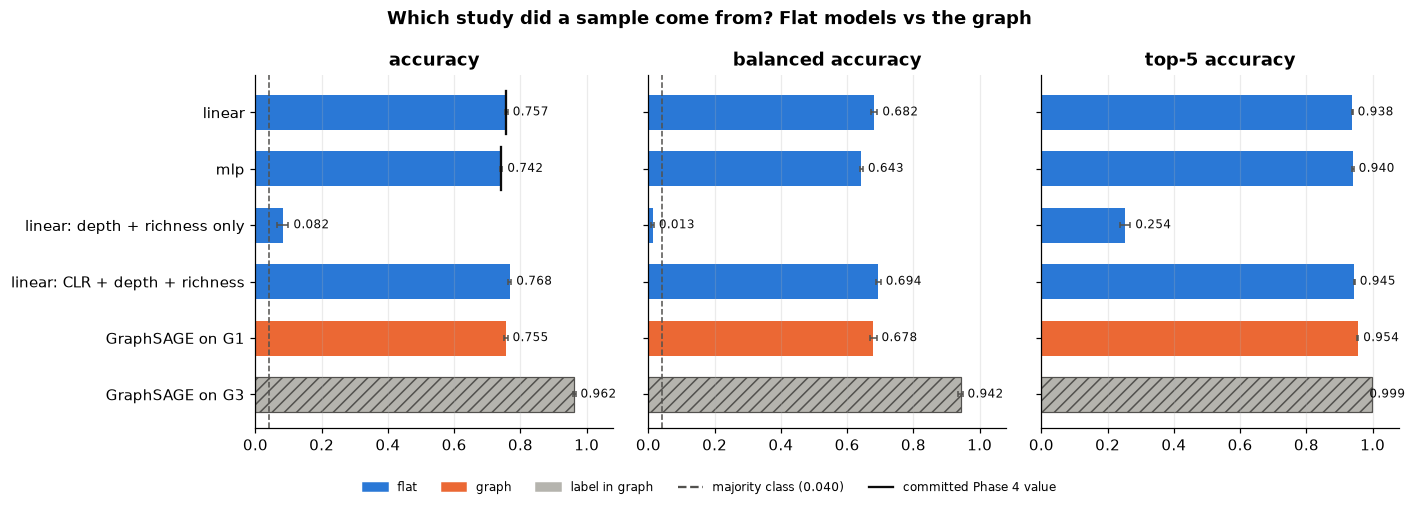

In [9]:
fig = gnn.plot_project_compare(summary, majority, committed=committed_acc)
fig.savefig(FIGURES / "phase7_project_compare.png")